<a href="https://colab.research.google.com/github/yevhenyatsyk7-hub/IBM_Quantum_experiments/blob/main/IBM_Qiskit_First_Run.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q qiskit qiskit-ibm-runtime

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-bigquery 3.46.2 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
holidays 0.107 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.


In [ ]:
import qiskit, qiskit_ibm_runtime
print(qiskit.__version__)
print(qiskit_ibm_runtime.__version__)

2.6.1
0.51.0


In [ ]:
from google.colab import userdata
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=userdata.get("IBM_TOKEN"),
    instance="open-instance",
)

for b in service.backends():
    print(b.name)

qiskit_runtime_service._discover_account:WARNING:2026-11-01 14:53:00,080: Loading account with the given token. A saved account will not be used.


ibm_fez
ibm_kingston
ibm_marrakesh


In [ ]:
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2

# Схема: стан Белла
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

# Вибір процесора і підготовка схеми під нього
backend = service.backend("ibm_kingston")
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_qc = pm.run(qc)

# Надсилання завдання
sampler = SamplerV2(mode=backend)
job = sampler.run([isa_qc], shots=1024)
print("ID завдання:", job.job_id())

/tmp/ipykernel_2256/2813089760.py:17: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


ID завдання: dbjl5d56p51s73cl11b0


In [ ]:
result = job.result()
print(result[0].data.meas.get_counts())

{'11': 457, '00': 543, '10': 8, '01': 16}


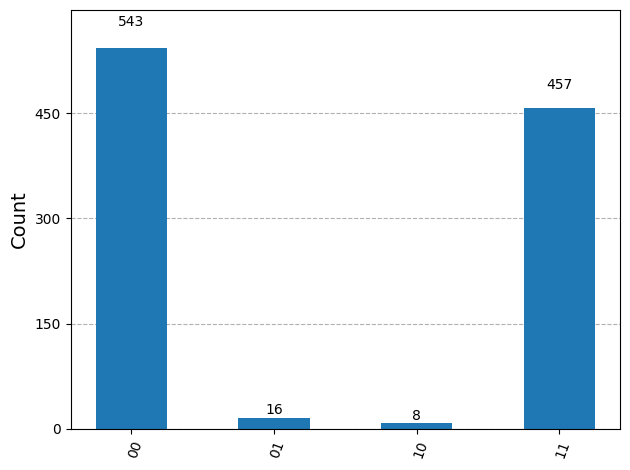

In [ ]:
from qiskit.visualization import plot_histogram
plot_histogram(result[0].data.meas.get_counts())

In [ ]:
!pip install -q qiskit-aer
from qiskit_aer import AerSimulator
print(AerSimulator().run(qc, shots=1024).result().get_counts())

{'00': 512, '11': 512}


In [ ]:
import numpy as np
from qiskit import QuantumCircuit

# Кути вимірювання: Аліса (кубіт 0) і Боб (кубіт 1)
alice = [0, np.pi/2]
bob   = [np.pi/4, -np.pi/4]

circuits = []
for a in alice:
    for b in bob:
        c = QuantumCircuit(2)
        c.h(0)
        c.cx(0, 1)          # стан Белла
        c.ry(-a, 0)         # повертаємо базис вимірювання Аліси
        c.ry(-b, 1)         # повертаємо базис вимірювання Боба
        c.measure_all()
        circuits.append(c)

print("Схем:", len(circuits))
circuits[1].draw()

Схем: 4


┌───┐      ┌───────┐  ░ ┌─┐   
   q_0: ┤ H ├──■───┤ Ry(0) ├──░─┤M├───
        └───┘┌─┴─┐┌┴───────┴┐ ░ └╥┘┌─┐
   q_1: ─────┤ X ├┤ Ry(π/4) ├─░──╫─┤M├
             └───┘└─────────┘ ░  ║ └╥┘
meas: 2/═════════════════════════╩══╩═
                                 0  1

In [ ]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2

backend = service.backend("ibm_kingston")
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuits = pm.run(circuits)

sampler = SamplerV2(mode=backend)
job = sampler.run(isa_circuits, shots=2048)
print("ID завдання:", job.job_id())

/tmp/ipykernel_2256/2250911355.py:8: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


ID завдання: dbjld90nceqs73ak82lg


In [ ]:
result = job.result()

def correlation(counts):
    total = sum(counts.values())
    same = counts.get('00', 0) + counts.get('11', 0)
    diff = counts.get('01', 0) + counts.get('10', 0)
    return (same - diff) / total

E = []
for i in range(4):
    counts = result[i].data.meas.get_counts()
    e = correlation(counts)
    E.append(e)
    print(f"Схема {i}: {counts} -> E = {e:.3f}")

S = E[0] - E[1] + E[2] + E[3]
print(f"\nS = {S:.3f}")

Схема 0: {'00': 900, '11': 800, '10': 167, '01': 181} -> E = 0.660
Схема 1: {'01': 192, '11': 775, '00': 901, '10': 180} -> E = 0.637
Схема 2: {'01': 188, '00': 923, '11': 782, '10': 155} -> E = 0.665
Схема 3: {'01': 901, '10': 829, '00': 190, '11': 128} -> E = -0.689

S = -0.001


/tmp/ipykernel_2256/1341425461.py:15: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  job = SamplerV2(mode=backend).run([isa], shots=SHOTS)


ID завдання: dbjlikd6p51s73cl1se0 - чекаємо результат...
Частка одиниць: сирі 0.4950 -> після XOR 0.4994

=== Результат (квантові випадкові числа) ===
Симуляцій: 3000
Медіана N:                 1.54e-12
N < 1 (ми сама в галактиці): 88.7%
Ймовірність бути самій:    88.0%
N > 1000:                  4.1%


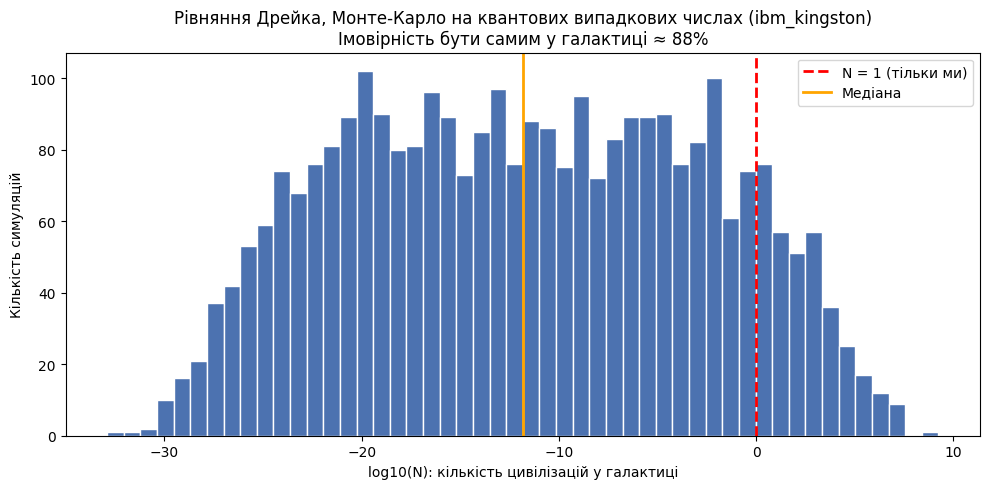

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2

# 1. Квантовий генератор: H на кожному кубіті + вимірювання
NQ, SHOTS = 128, 10000
qc = QuantumCircuit(NQ)
qc.h(range(NQ))
qc.measure_all()

backend = service.backend("ibm_kingston")
isa = generate_preset_pass_manager(backend=backend, optimization_level=1).run(qc)
job = SamplerV2(mode=backend).run([isa], shots=SHOTS)
print("ID завдання:", job.job_id(), "- чекаємо результат...")

bitstrings = job.result()[0].data.meas.get_bitstrings()
raw = np.array([list(s) for s in bitstrings], dtype=np.uint8).ravel()

# 2. Зменшуємо зсув: XOR сусідніх пар бітів (помилки зчитування схиляють до 0)
bits = raw[0::2] ^ raw[1::2]
print(f"Частка одиниць: сирі {raw.mean():.4f} -> після XOR {bits.mean():.4f}")

# 3. Перетворюємо біти на рівномірні числа u в [0, 1)
N_SIM, B, PARAMS = 3000, 24, 7
bits = bits[: PARAMS * N_SIM * B].reshape(PARAMS, N_SIM, B)
u = (bits * 2.0 ** -np.arange(1, B + 1)).sum(axis=2)

def loguni(i, lo, hi):
    return 10 ** (np.log10(lo) + u[i] * (np.log10(hi) - np.log10(lo)))

# 4. Рівняння Дрейка
R  = loguni(0, 1, 100)
fp = loguni(1, 0.1, 1)
ne = loguni(2, 0.1, 1)
fl = loguni(3, 1e-30, 1)
fi = loguni(4, 1e-3, 1)
fc = loguni(5, 1e-2, 1)
L  = loguni(6, 1e2, 1e10)
N = R * fp * ne * fl * fi * fc * L

alone = np.mean(np.exp(-N))
print("\n=== Результат (квантові випадкові числа) ===")
print(f"Симуляцій: {N_SIM}")
print(f"Медіана N:                 {np.median(N):.3g}")
print(f"N < 1 (ми сама в галактиці): {np.mean(N < 1):.1%}")
print(f"Ймовірність бути самій:    {alone:.1%}")
print(f"N > 1000:                  {np.mean(N > 1000):.1%}")

# 5. Графік
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(np.log10(N), bins=50, color="#4c72b0", edgecolor="white")
ax.axvline(0, color="red", ls="--", lw=2, label="N = 1 (тільки ми)")
ax.axvline(np.log10(np.median(N)), color="orange", lw=2, label="Медіана")
ax.set_xlabel("log10(N): кількість цивілізацій у галактиці")
ax.set_ylabel("Кількість симуляцій")
ax.set_title(f"Рівняння Дрейка, Монте-Карло на квантових випадкових числах (ibm_kingston)\nІмовірність бути самим у галактиці ≈ {alone:.0%}")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2

SIZES = list(range(2, 41, 2))   # 2, 4, ..., 40 кубітів
SHOTS = 20000
BACKENDS = ["ibm_fez", "ibm_kingston", "ibm_marrakesh"]

def ghz(n):
    qc = QuantumCircuit(n)
    qc.h(0)
    for i in range(n - 1):
        qc.cx(i, i + 1)
    qc.measure_all()
    return qc

circuits = [ghz(n) for n in SIZES]

# 1. Надсилаємо завдання на всі три процесори (вони виконуються паралельно)
jobs = {}
for name in BACKENDS:
    be = service.backend(name)
    pm = generate_preset_pass_manager(backend=be, optimization_level=3)
    isa = pm.run(circuits)
    jobs[name] = SamplerV2(mode=be).run(isa, shots=SHOTS)
    print(f"{name}: ID {jobs[name].job_id()}")

print("\nЧекаємо результати (може тривати кілька хвилин)...")

# 2. Збираємо результати
fid = {}
for name, job in jobs.items():
    res = job.result()
    fid[name] = []
    for n, r in zip(SIZES, res):
        c = r.data.meas.get_counts()
        f = (c.get("0" * n, 0) + c.get("1" * n, 0)) / SHOTS
        fid[name].append(f)
    print(f"{name}: готово")

# 3. Графік
fig, ax = plt.subplots(figsize=(10, 5.5))
for name in BACKENDS:
    ax.plot(SIZES, fid[name], marker="o", label=name)
ax.axhline(0.5, color="red", ls="--", label="F = 0.5 (межа справжньої заплутаності)")
ax.set_yscale("log")
ax.set_xlabel("Кількість кубітів у GHZ-стані")
ax.set_ylabel("F = P(всі 0) + P(всі 1)")
ax.set_title("Як шум руйнує заплутаність: GHZ на трьох процесорах IBM")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

for name in BACKENDS:
    ok = [n for n, f in zip(SIZES, fid[name]) if f > 0.5]
    print(f"{name}: заплутаність підтверджена до {max(ok) if ok else '<2'} кубітів")

/tmp/ipykernel_2256/2691671223.py:26: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  jobs[name] = SamplerV2(mode=be).run(isa, shots=SHOTS)


ibm_fez: ID dbjlnjhkdqps7390r5ng
ibm_kingston: ID dbjlnl8nceqs73ak8msg
ibm_marrakesh: ID dbjlnm9kdqps7390r5s0

Чекаємо результати (може тривати кілька хвилин)...
ibm_fez: готово
ibm_kingston: готово


KeyboardInterrupt: 

In [ ]:
job = service.job("dbjlnm9kdqps7390r5s0")
print(job.status())

QUEUED


In [3]:
from google.colab import userdata
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=userdata.get("IBM_TOKEN"),
    instance="open-instance",
)
for name, jid in [("fez", "dbjlnjhkdqps7390r5ng"),
                  ("kingston", "dbjlnl8nceqs73ak8msg"),
                  ("marrakesh", "dbjlnm9kdqps7390r5s0")]:
    print(name, service.job(jid).status())


qiskit_runtime_service._discover_account:WARNING:2026-11-02 15:02:48,864: Loading account with the given token. A saved account will not be used.


fez DONE
kingston DONE
marrakesh DONE


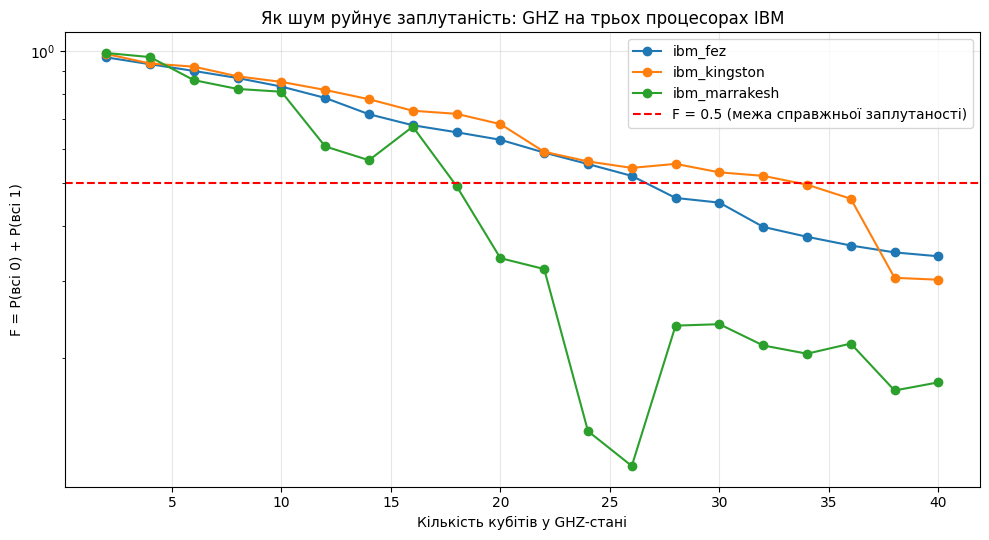

ibm_fez: F>0.5 до 26 кубітів
ibm_kingston: F>0.5 до 32 кубітів
ibm_marrakesh: F>0.5 до 16 кубітів


In [4]:
import matplotlib.pyplot as plt

SIZES = list(range(2, 41, 2))
SHOTS = 20000
JOBS = {
    "ibm_fez": "dbjlnjhkdqps7390r5ng",
    "ibm_kingston": "dbjlnl8nceqs73ak8msg",
    "ibm_marrakesh": "dbjlnm9kdqps7390r5s0",
}

fid = {}
for name, jid in JOBS.items():
    res = service.job(jid).result()
    fid[name] = []
    for n, r in zip(SIZES, res):
        c = r.data.meas.get_counts()
        fid[name].append((c.get("0" * n, 0) + c.get("1" * n, 0)) / SHOTS)

fig, ax = plt.subplots(figsize=(10, 5.5))
for name, f in fid.items():
    ax.plot(SIZES, f, marker="o", label=name)
ax.axhline(0.5, color="red", ls="--", label="F = 0.5 (межа справжньої заплутаності)")
ax.set_yscale("log")
ax.set_xlabel("Кількість кубітів у GHZ-стані")
ax.set_ylabel("F = P(всі 0) + P(всі 1)")
ax.set_title("Як шум руйнує заплутаність: GHZ на трьох процесорах IBM")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

for name, f in fid.items():
    ok = [n for n, v in zip(SIZES, f) if v > 0.5]
    print(f"{name}: F>0.5 до {max(ok) if ok else '<2'} кубітів")